O objetivo é encontrar uma definicação ideal apra o formato dos superpixel, que vão virar os nós da rede

In [40]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from skimage.segmentation import slic, mark_boundaries
import glob
import numpy as np
import pandas as pd
from PIL import Image
from skimage.color import rgb2gray
from skimage.feature import canny
from skimage.segmentation import slic, find_boundaries
from scipy.ndimage import distance_transform_edt

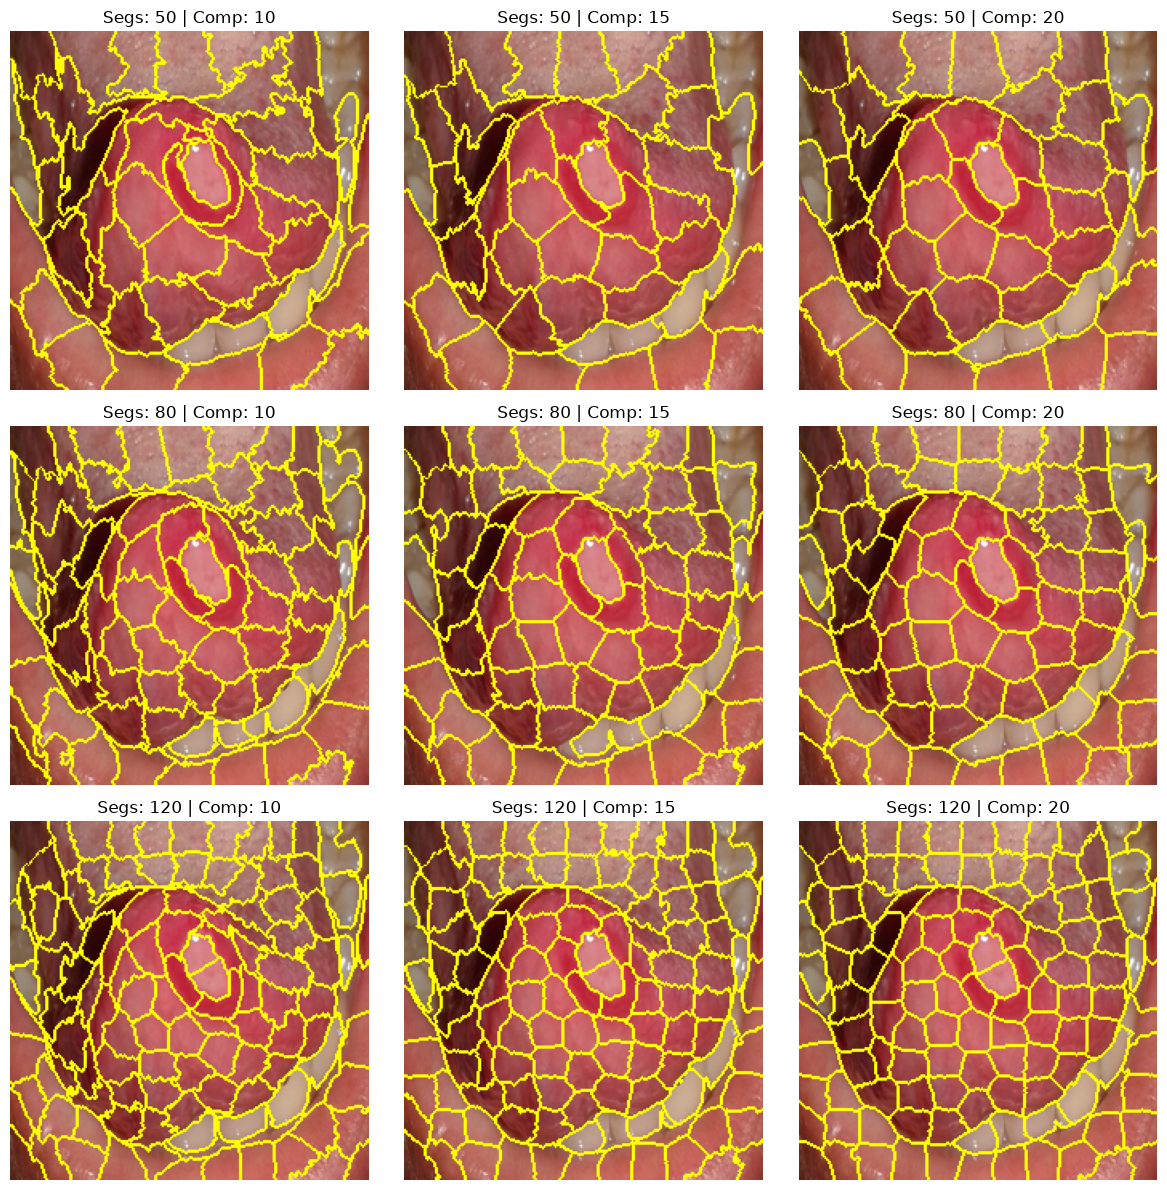

In [41]:
# Função para carregar a imagem e redimensionar para o padrão combinado com o Luiz
def carregar_imagem(caminho):
    img = Image.open(caminho).convert("RGB").resize((224, 224))
    return np.array(img)


#  Exemplo com a benigna

caminho_img = "../data/original_data/benign_lesions/1.jpg" 
img_np = carregar_imagem(caminho_img)

# Testando diferentes granularidades e formatos
n_segments_list = [50, 80, 120]
compactness_list = [10, 15, 20]

fig, axes = plt.subplots(len(n_segments_list), len(compactness_list), figsize=(12, 12))

for i, n_seg in enumerate(n_segments_list):
    for j, comp in enumerate(compactness_list):
        # start_label=0 é vital para mapearmos os IDs dos nós de 0 a N amanhã
        segments = slic(img_np, n_segments=n_seg, compactness=comp, start_label=0)
        
        ax = axes[i, j]
        ax.imshow(mark_boundaries(img_np, segments))
        ax.set_title(f"Segs: {n_seg} | Comp: {comp}")
        ax.axis("off")

plt.tight_layout()
plt.show()

O melhor visaulmente foi o Segs 80 e Comp 15

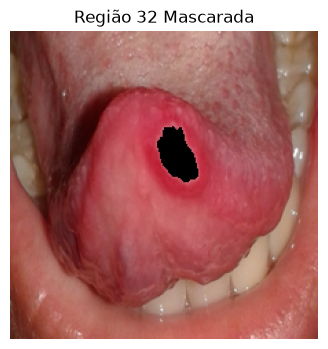

In [42]:
# Gerando a segmentação final com os parâmetros escolhidos
segments_final = slic(img_np, n_segments=80, compactness=15, start_label=0)

# Mapeamento região -> pixels (coração da nossa perturbação)
num_nodes = segments_final.max() + 1
regiao_para_pixels = {node_id: np.where(segments_final == node_id) for node_id in range(num_nodes)}

# Copia a imagem original para mascarar
img_mascarada = img_np.copy()

# Escolhendo uma região arbitrária para desligar (ex: id 15)
id_regiao = 32
img_mascarada[regiao_para_pixels[id_regiao]] = [0, 0, 0] # Pinta de preto

# Visualiza o resultado
plt.figure(figsize=(4, 4))
plt.imshow(img_mascarada)
plt.title(f"Região {id_regiao} Mascarada")
plt.axis("off")
plt.show()

In [43]:
def boundary_recall(img_np: np.ndarray, segments: np.ndarray, tol: int = 2) -> float:
    """Calcula a fração de bordas (Canny) cobertas pelas fronteiras SLIC dentro de `tol` pixels."""
    gray = rgb2gray(img_np)
    ref_edges = canny(gray, sigma=1.5)
    if not np.any(ref_edges):
        return 0.0
    
    slic_bounds = find_boundaries(segments, mode="thick")
    # Distância de cada pixel até a fronteira SLIC mais próxima
    dist_to_slic = distance_transform_edt(~slic_bounds)
    
    matched_edges = ref_edges & (dist_to_slic <= tol)
    return float(matched_edges.sum() / ref_edges.sum())

# Amostra de 10 imagens (5 benignas, 5 malignas) para calibrar os hiperparâmetros
amostras = (
    sorted(glob.glob("../data/original_data/benign_lesions/*.jpg"))[:5] +
    sorted(glob.glob("../data/original_data/malignant_lesions/*.jpg"))[:5]
)

resultados = []
for n_seg in [40, 70, 100]:
    for comp in [5, 10, 20]:
        recalls, nos_reais = [], []
        for path in amostras:
            img = np.asarray(Image.open(path).convert("RGB").resize((224, 224)), dtype=np.float32) / 255.0
            segs = slic(img, n_segments=n_seg, compactness=comp, start_label=0)
            recalls.append(boundary_recall(img, segs, tol=2))
            nos_reais.append(int(segs.max() + 1))
            
        resultados.append({
            "n_segments": n_seg,
            "compactness": comp,
            "nos_medios": round(np.mean(nos_reais), 1),
            "boundary_recall_mean": round(np.mean(recalls), 4),
            "boundary_recall_std": round(np.std(recalls), 4),
        })

df_slic = pd.DataFrame(resultados)
display(df_slic)

,n_segments,compactness,nos_medios,boundary_recall_mean,boundary_recall_std
0,40,5,27.5,0.5098,0.0739
1,40,10,33.0,0.5353,0.0708
2,40,20,35.5,0.4587,0.0547
3,70,5,50.5,0.6306,0.0788
4,70,10,57.5,0.6258,0.0511
5,70,20,62.3,0.5318,0.0492
6,100,5,79.2,0.6932,0.0720
7,100,10,91.7,0.7134,0.0479
8,100,20,98.3,0.6237,0.0439


 (70, 10): Tem uma média de 57,5 nós e um boundary recall de 0.6258 ($\pm 0.0511$). É um grafo bem enxuto e rápido de processar na API, mas deixa escapar cerca de 37% das bordas de referência

 (100, 20): Tem uma média de 98,3 nós e um boundary recall de 0.6237 ($\pm 0.0439$).

In [44]:
N_SEGMENTS, COMPACTNESS= 70, 10 

In [45]:
import sys
sys.path.append("..")  # garante que o Python encontre a pasta src/
importlib.reload(src.explainability)
import torch
import matplotlib.pyplot as plt
from PIL import Image
from src.modelo_treinado import CNN
from src.explainability import SuperpixelGraphExplainer
import importlib
import src.modelo_treinado
importlib.reload(src.modelo_treinado)
from src.modelo_treinado import CNNLightning


model = CNNLightning.load_from_checkpoint("../models/cnn_geral.ckpt", map_location="cpu")
explainer = SuperpixelGraphExplainer(model, n_segments=70, compactness=10, num_samples=150)

amostras_visuais = [
    
    ("Benigno 1", "../data/augmented_data/augmented_benign/1.jpg"),
    ("Benigno 2", "../data/augmented_data/augmented_benign/2.jpg"),
    ("Maligno 1", "../data/augmented_data/augmented_malignant/1.jpg"),
    ("Maligno 2", "../data/augmented_data/augmented_malignant/2.jpg"),
]


/home/jaimewillian/Documentos/FGV/6P/DL 2/api-oncolens/.env/lib/python3.14/site-packages/lightning/pytorch/utilities/migration/utils.py:56: The loaded checkpoint was produced with Lightning v2.5.5, which is newer than your current Lightning version: v2.4.0


Benigno 1
Probabilidade num_superpixels fidelity_drop_top5
0.3145711123943329 61 0.4160136282444
Benigno 2
Probabilidade num_superpixels fidelity_drop_top5
0.3037790060043335 60 0.029456257820129395
Maligno 1
Probabilidade num_superpixels fidelity_drop_top5
0.40915536880493164 55 0.07324719429016113
Maligno 2
Probabilidade num_superpixels fidelity_drop_top5
0.6819066405296326 58 0.16210323572158813


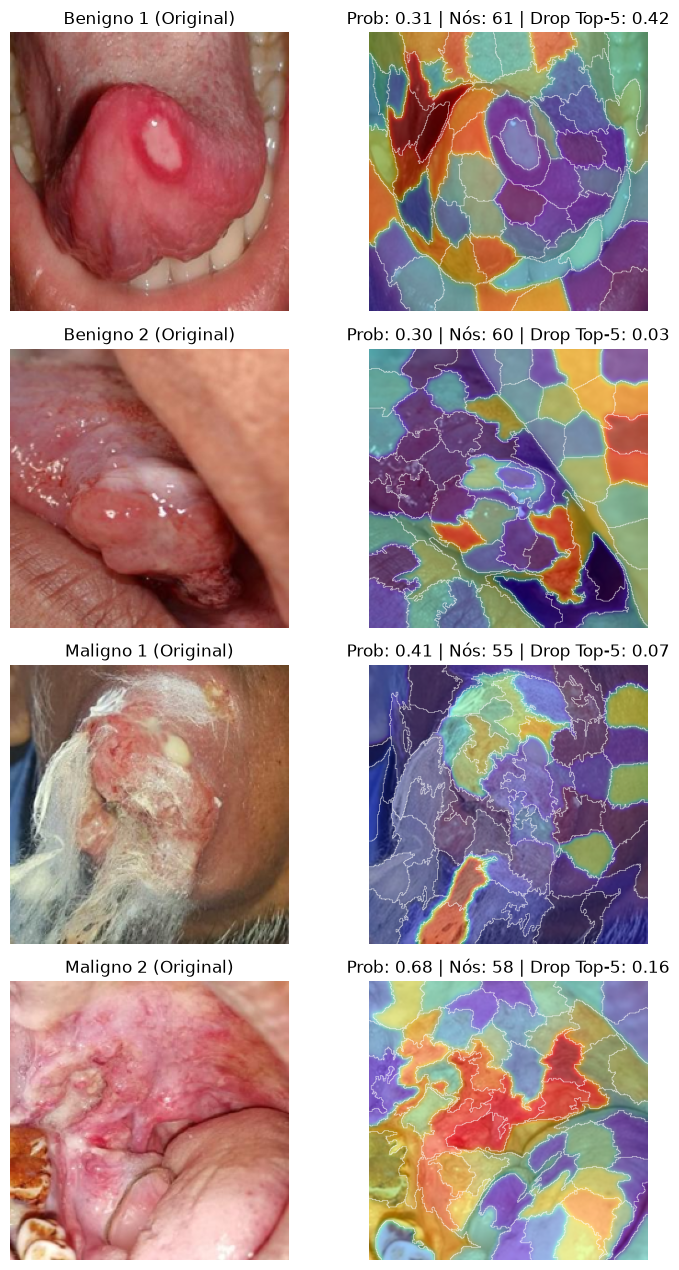

In [46]:

fig, axes = plt.subplots(len(amostras_visuais), 2, figsize=(8, 3.2 * len(amostras_visuais)))

for idx, (titulo, path) in enumerate(amostras_visuais):
    img = Image.open(path).convert("RGB").resize((224, 224))
    res = explainer.explain(img)
    print(titulo)
    print('Probabilidade', 'num_superpixels','fidelity_drop_top5')
    print(res['probabilidade'], res['num_superpixels'], res['fidelity_drop_top5'])
    
    axes[idx, 0].imshow(img)
    axes[idx, 0].set_title(f"{titulo} (Original)")
    axes[idx, 0].axis("off")
    
    axes[idx, 1].imshow(res["overlay_image"])
    axes[idx, 1].set_title(
        f"Prob: {res['probabilidade']:.2f} | Nós: {res['num_superpixels']} | Drop Top-5: {res['fidelity_drop_top5']:.2f}"
    )
    axes[idx, 1].axis("off")

plt.tight_layout()
plt.savefig("../figuras_explicacoes_baseline.png", dpi=200)
plt.show()

In [47]:
res['probabilidade'], res['num_superpixels'], res['fidelity_drop_top5']

(0.6819066405296326, 58, 0.16210323572158813)